# ==========================================
# 1. Import libraries and load the dataset
# ==========================================

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

# Set visual aesthetic theme
sns.set_theme(style="whitegrid")

# Load the dataset (supports execution from both repo root and tp01/)
data_path = "train.csv" if os.path.exists("train.csv") else os.path.join("tp01", "train.csv")
df = pd.read_csv(data_path)

# Display the first few rows of the dataset
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


# ==========================================
# 2. Explore the dataset
# ==========================================

In [2]:
# Get the number of rows and columns
df.shape

(891, 12)

In [3]:
# Display information about columns, non-null counts and data types
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 118.9 KB


In [4]:
# Print data types of all columns in df
print("Data types of df:")
print(df.dtypes)

Data types of df:
PassengerId      int64
Survived         int64
Pclass           int64
Name               str
Sex                str
Age            float64
SibSp            int64
Parch            int64
Ticket             str
Fare           float64
Cabin              str
Embarked           str
dtype: object


In [5]:
# Generate descriptive statistics for numerical columns
df.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


# ==========================================
# 3. Select and filter data
# ==========================================

In [6]:
# Display the first 6 female passengers
df[df["Sex"] == "female"].head(6)

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
8,9,1,3,"Johnson, Mrs. Oscar W (Elisabeth Vilhelmina Berg)",female,27.0,0,2,347742,11.1333,NaN,S
9,10,1,2,"Nasser, Mrs. Nicholas (Adele Achem)",female,14.0,1,0,237736,30.0708,NaN,C
10,11,1,3,"Sandstrom, Miss. Marguerite Rut",female,4.0,1,1,PP 9549,16.7000,G6,S


In [7]:
# Display the first 6 male passengers older than 70
df[(df["Sex"] == "male") & (df["Age"] > 70)].head(6)

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
96,97,0,1,"Goldschmidt, Mr. George B",male,71.0,0,0,PC 17754,34.6542,A5,C
116,117,0,3,"Connors, Mr. Patrick",male,70.5,0,0,370369,7.7500,NaN,Q
493,494,0,1,"Artagaveytia, Mr. Ramon",male,71.0,0,0,PC 17609,49.5042,NaN,C
630,631,1,1,"Barkworth, Mr. Algernon Henry Wilson",male,80.0,0,0,27042,30.0000,A23,S
851,852,0,3,"Svensson, Mr. Johan",male,74.0,0,0,347060,7.7750,NaN,S


# ==========================================
# 4. Detect missing values
# ==========================================

In [8]:
# Count missing values in each column
df.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

In [9]:
# Count missing values in each row and sort in descending order
df.isnull().sum(axis=1).sort_values(ascending=False).head(10)

5      2
19     2
17     2
674    2
32     2
29     2
28     2
26     2
667    2
692    2
dtype: int64

# ==========================================
# 5. Handle missing values
# ==========================================

In [10]:
# Replace missing Age values with the median
df["Age"] = df["Age"].fillna(df["Age"].median())

In [11]:
# Replace missing Embarked values with the most frequent value (mode)
df["Embarked"] = df["Embarked"].fillna(df["Embarked"].mode()[0])

# ==========================================
# 6. Detect and remove duplicates
# ==========================================

In [12]:
# Count duplicated rows
df.duplicated().sum()

np.int64(0)

In [13]:
# Remove duplicated rows if any
df = df.drop_duplicates()
print("Shape after drop_duplicates:", df.shape)

Shape after drop_duplicates: (891, 12)


# ==========================================
# 7. Transform and rename data
# ==========================================

In [14]:
# Replace "female" with "F" and "male" with "M"
df["Sex"] = df["Sex"].replace({"female": "F", "male": "M"})
df["Sex"].head(6)

0    M
1    F
2    F
3    F
4    M
5    M
Name: Sex, dtype: str

In [15]:
# Rename columns: Pclass -> passenger_class, Sex -> gender
df.rename(columns={"Pclass": "passenger_class", "Sex": "gender"}, inplace=True)
print("Updated columns:")
print(df.columns.tolist())
df.head()

Updated columns:
['PassengerId', 'Survived', 'passenger_class', 'Name', 'gender', 'Age', 'SibSp', 'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked']


,PassengerId,Survived,passenger_class,Name,gender,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",M,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",F,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",F,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",F,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",M,35.0,0,0,373450,8.0500,NaN,S


# ==========================================
# 8. Explore unique values, frequencies and data counts
# ==========================================

In [16]:
# Count unique passengers using nunique()
print("Number of unique passengers (PassengerId):", df["PassengerId"].nunique())

# Count unique values across all numerical columns using nunique()
print("\nUnique values count across numerical columns:")
print(df.select_dtypes(include=np.number).nunique())

Number of unique passengers (PassengerId): 891

Unique values count across numerical columns:
PassengerId        891
Survived             2
passenger_class      3
Age                 88
SibSp                7
Parch                7
Fare               248
dtype: int64


In [17]:
# Display data count (non-null counts for each column)
print(f"Total rows in dataset: {len(df)}")
print("\nNon-null count per column (data count):")
print(df.count())

Total rows in dataset: 891

Non-null count per column (data count):
PassengerId        891
Survived           891
passenger_class    891
Name               891
gender             891
Age                891
SibSp              891
Parch              891
Ticket             891
Fare               891
Cabin              204
Embarked           891
dtype: int64


In [18]:
# Display unique values in Embarked
df["Embarked"].unique()

<ArrowStringArray>
['S', 'C', 'Q']
Length: 3, dtype: str

In [19]:
# Count the frequency of each value in Embarked
df["Embarked"].value_counts()

Embarked
S    646
C    168
Q     77
Name: count, dtype: int64

# ==========================================
# 9. Basic statistical operation
# ==========================================

In [20]:
# Get the maximum ticket fare
max_fare = df["Fare"].max()
print(f"Maximum ticket fare: {max_fare:.2f}")

Maximum ticket fare: 512.33


# ==========================================
# 10. Data Distribution and Age Analysis
# ==========================================

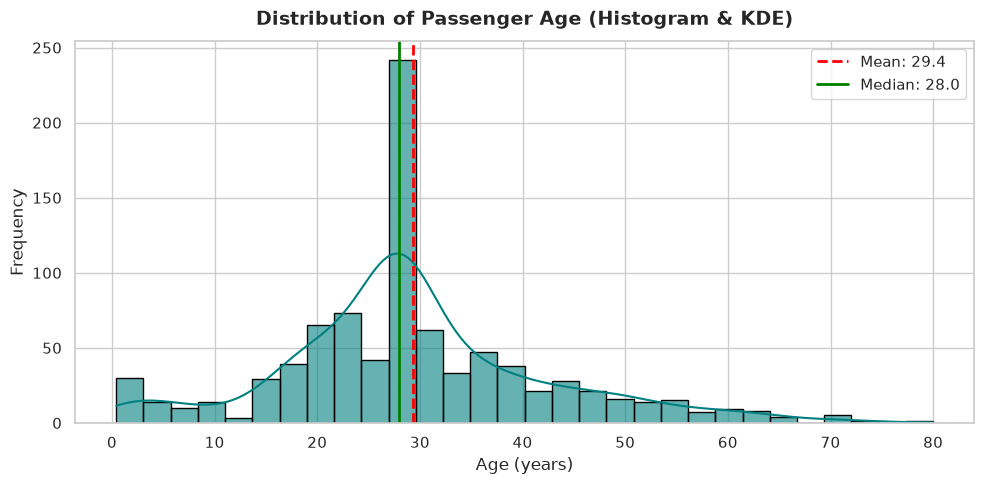

In [21]:
# Plot distribution of Age with Histogram and KDE
plt.figure(figsize=(10, 5))
sns.histplot(df["Age"], kde=True, bins=30, color="teal", edgecolor="black", alpha=0.6)
plt.title("Distribution of Passenger Age (Histogram & KDE)", fontsize=14, fontweight="bold", pad=12)
plt.xlabel("Age (years)", fontsize=12)
plt.ylabel("Frequency", fontsize=12)
plt.axvline(df["Age"].mean(), color="red", linestyle="--", linewidth=2, label=f"Mean: {df['Age'].mean():.1f}")
plt.axvline(df["Age"].median(), color="green", linestyle="-", linewidth=2, label=f"Median: {df['Age'].median():.1f}")
plt.legend(fontsize=11)
plt.tight_layout()
plt.show()

# ==========================================
# 11. Detect Outliers using Box Plot and Scatter Plot
# ==========================================

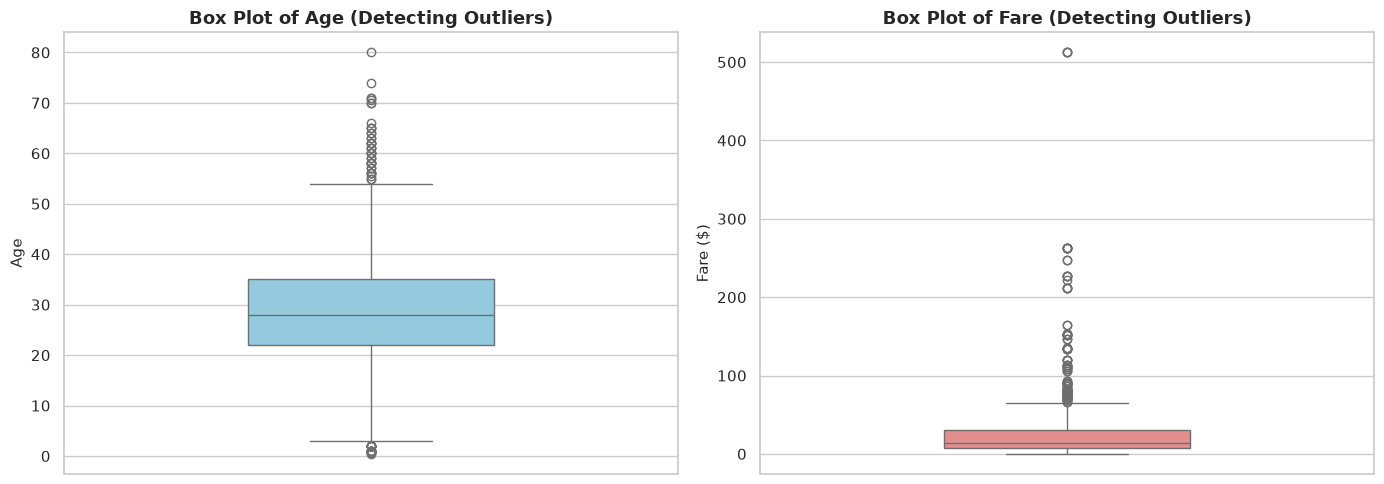

In [22]:
# Box plots for detecting univariate outliers in Age and Fare
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Box plot for Age
sns.boxplot(y=df["Age"], ax=axes[0], color="skyblue", width=0.4)
axes[0].set_title("Box Plot of Age (Detecting Outliers)", fontsize=13, fontweight="bold")
axes[0].set_ylabel("Age", fontsize=11)

# Box plot for Fare
sns.boxplot(y=df["Fare"], ax=axes[1], color="lightcoral", width=0.4)
axes[1].set_title("Box Plot of Fare (Detecting Outliers)", fontsize=13, fontweight="bold")
axes[1].set_ylabel("Fare ($)", fontsize=11)

plt.tight_layout()
plt.show()

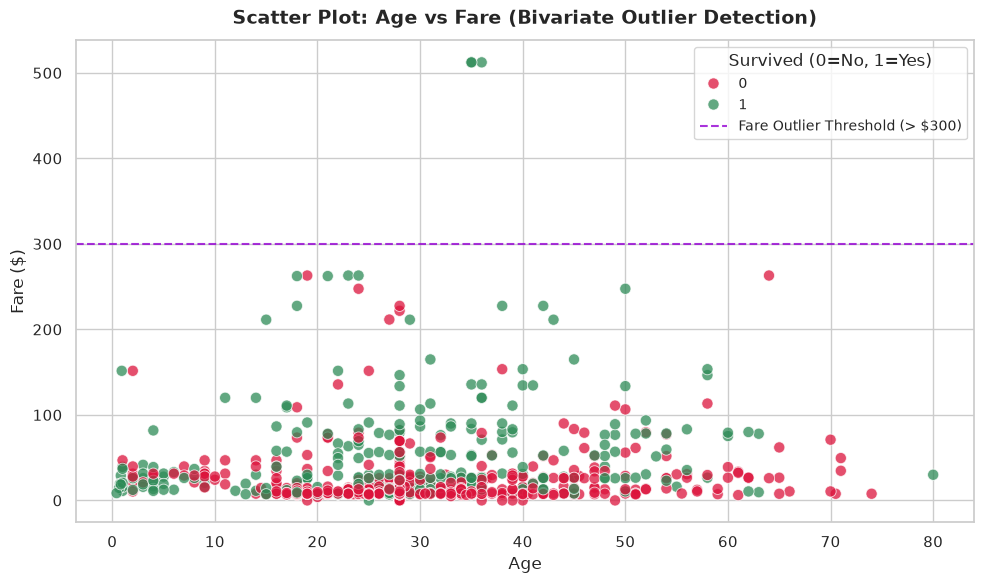

In [23]:
# Scatter plot for detecting bivariate outliers (Age vs Fare)
plt.figure(figsize=(10, 6))
sns.scatterplot(
    x="Age", 
    y="Fare", 
    hue="Survived", 
    data=df, 
    palette={0: "crimson", 1: "seagreen"}, 
    alpha=0.75, 
    s=65
)
plt.title("Scatter Plot: Age vs Fare (Bivariate Outlier Detection)", fontsize=14, fontweight="bold", pad=12)
plt.xlabel("Age", fontsize=12)
plt.ylabel("Fare ($)", fontsize=12)
plt.axhline(300, color="darkviolet", linestyle="--", alpha=0.8, label="Fare Outlier Threshold (> $300)")
plt.legend(title="Survived (0=No, 1=Yes)", fontsize=10)
plt.tight_layout()
plt.show()

# ==========================================
# 12. Outlier Detection using Z-Score and IQR
# ==========================================

In [24]:
from scipy import stats

# 1. Outlier detection using Z-Scores (|Z| > 3)
z_scores_age = stats.zscore(df["Age"])
z_outliers_age = df[np.abs(z_scores_age) > 3]

z_scores_fare = stats.zscore(df["Fare"])
z_outliers_fare = df[np.abs(z_scores_fare) > 3]

print("=== Z-SCORE OUTLIER DETECTION (|Z| > 3) ===")
print(f"Age outliers count:  {len(z_outliers_age)} ({(len(z_outliers_age)/len(df))*100:.2f}%)")
print(f"Fare outliers count: {len(z_outliers_fare)} ({(len(z_outliers_fare)/len(df))*100:.2f}%)")
print("\nTop Fare Outliers (|Z| > 3):")
display(z_outliers_fare[["PassengerId", "passenger_class", "gender", "Age", "Fare"]].head())

=== Z-SCORE OUTLIER DETECTION (|Z| > 3) ===
Age outliers count:  7 (0.79%)
Fare outliers count: 20 (2.24%)

Top Fare Outliers (|Z| > 3):


,PassengerId,passenger_class,gender,Age,Fare
27,28,1,M,19.0,263.0000
88,89,1,F,23.0,263.0000
118,119,1,M,24.0,247.5208
258,259,1,F,35.0,512.3292
299,300,1,F,50.0,247.5208


In [25]:
# 2. Outlier detection using IQR (Interquartile Range - Tukey's Fences)
def detect_iqr_outliers(series, column_name):
    q1 = series.quantile(0.25)
    q3 = series.quantile(0.75)
    iqr = q3 - q1
    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr
    outliers = series[(series < lower_bound) | (series > upper_bound)]
    print(f"--- IQR Analysis for '{column_name}' ---")
    print(f"  Q1 (25th percentile): {q1:.2f}")
    print(f"  Q3 (75th percentile): {q3:.2f}")
    print(f"  IQR:                 {iqr:.2f}")
    print(f"  Lower Bound:         {lower_bound:.2f}")
    print(f"  Upper Bound:         {upper_bound:.2f}")
    print(f"  Number of Outliers:  {len(outliers)} ({len(outliers)/len(series)*100:.2f}%)\n")
    return lower_bound, upper_bound, outliers

low_age, up_age, age_iqr_outliers = detect_iqr_outliers(df["Age"], "Age")
low_fare, up_fare, fare_iqr_outliers = detect_iqr_outliers(df["Fare"], "Fare")

--- IQR Analysis for 'Age' ---
  Q1 (25th percentile): 22.00
  Q3 (75th percentile): 35.00
  IQR:                 13.00
  Lower Bound:         2.50
  Upper Bound:         54.50
  Number of Outliers:  66 (7.41%)

--- IQR Analysis for 'Fare' ---
  Q1 (25th percentile): 7.91
  Q3 (75th percentile): 31.00
  IQR:                 23.09
  Lower Bound:         -26.72
  Upper Bound:         65.63
  Number of Outliers:  116 (13.02%)



# ==========================================
# 13. Data Normalization and Scaling
# ==========================================

In [26]:
from sklearn.preprocessing import MinMaxScaler, StandardScaler, RobustScaler

# Extract numerical columns for scaling comparison
scaling_data = df[["Age", "Fare"]].copy()

# Technique 1: Min-Max Normalization (Rescales to range [0, 1])
minmax_scaler = MinMaxScaler()
df_minmax = pd.DataFrame(
    minmax_scaler.fit_transform(scaling_data), 
    columns=["Age_MinMax", "Fare_MinMax"],
    index=scaling_data.index
)

# Technique 2: Standard Scaling / Z-Score Standardization (Mean=0, Std=1)
standard_scaler = StandardScaler()
df_standard = pd.DataFrame(
    standard_scaler.fit_transform(scaling_data), 
    columns=["Age_Standard", "Fare_Standard"],
    index=scaling_data.index
)

# Technique 3: Robust Scaling (Uses Median & IQR - resilient to outliers)
robust_scaler = RobustScaler()
df_robust = pd.DataFrame(
    robust_scaler.fit_transform(scaling_data), 
    columns=["Age_Robust", "Fare_Robust"],
    index=scaling_data.index
)

# Combine for comparison
scaled_comparison = pd.concat([scaling_data, df_minmax, df_standard, df_robust], axis=1)
print("=== COMPARISON OF SCALED FEATURES (First 5 Rows) ===")
display(scaled_comparison.head())

print("\n=== DESCRIPTIVE STATISTICS OF SCALED FEATURES ===")
display(scaled_comparison.describe().round(3))


=== COMPARISON OF SCALED FEATURES (First 5 Rows) ===


,Age,Fare,Age_MinMax,Fare_MinMax,Age_Standard,Fare_Standard,Age_Robust,Fare_Robust
0,22.0,7.2500,0.271174,0.014151,-0.565736,-0.502445,-0.461538,-0.312011
1,38.0,71.2833,0.472229,0.139136,0.663861,0.786845,0.769231,2.461242
2,26.0,7.9250,0.321438,0.015469,-0.258337,-0.488854,-0.153846,-0.282777
3,35.0,53.1000,0.434531,0.103644,0.433312,0.420730,0.538462,1.673732
4,35.0,8.0500,0.434531,0.015713,0.433312,-0.486337,0.538462,-0.277363



=== DESCRIPTIVE STATISTICS OF SCALED FEATURES ===


,Age,Fare,Age_MinMax,Fare_MinMax,Age_Standard,Fare_Standard,Age_Robust,Fare_Robust
count,891.000,891.000,891.000,891.000,891.000,891.000,891.000,891.000
mean,29.362,32.204,0.364,0.063,0.000,0.000,0.105,0.769
std,13.020,49.693,0.164,0.097,1.001,1.001,1.002,2.152
min,0.420,0.000,0.000,0.000,-2.224,-0.648,-2.122,-0.626
25%,22.000,7.910,0.271,0.015,-0.566,-0.489,-0.462,-0.283
50%,28.000,14.454,0.347,0.028,-0.105,-0.357,0.000,0.000
75%,35.000,31.000,0.435,0.061,0.433,-0.024,0.538,0.717
max,80.000,512.329,1.000,1.000,3.892,9.667,4.000,21.563


# ==========================================
# 14. Data Discretization and Binning (Age)
# ==========================================

Quantile-based Discretization (q=3) Counts:
Age_binned_q3
bins1    301
bins2    304
bins3    286
Name: count, dtype: int64

Equal-Width Discretization (3 intervals) Counts:
Age_binned_cut3
bins1    319
bins2    522
bins3     50
Name: count, dtype: int64


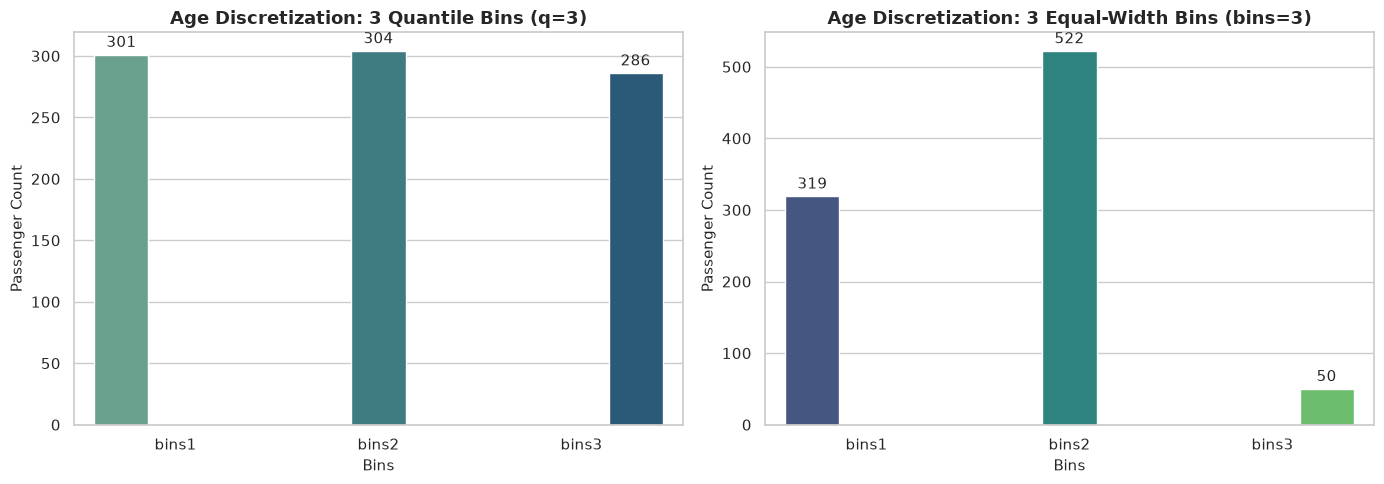

In [27]:
# Discretize 'Age' into 3 bins with labels ['bins1', 'bins2', 'bins3']

# Method 1: Quantile-based Discretization (q=3: Equal Frequency Bins)
df["Age_binned_q3"] = pd.qcut(df["Age"], q=3, labels=["bins1", "bins2", "bins3"])

# Method 2: Equal-Width Discretization (bins=3: Equal Interval Ranges)
df["Age_binned_cut3"] = pd.cut(df["Age"], bins=3, labels=["bins1", "bins2", "bins3"])

print("Quantile-based Discretization (q=3) Counts:")
print(df["Age_binned_q3"].value_counts().sort_index())

print("\nEqual-Width Discretization (3 intervals) Counts:")
print(df["Age_binned_cut3"].value_counts().sort_index())

# Plot Histograms of Discretized Age Bins
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Quantile Bins
sns.countplot(x=df["Age_binned_q3"], hue=df["Age_binned_q3"], ax=axes[0], palette="crest", legend=False)
axes[0].set_title("Age Discretization: 3 Quantile Bins (q=3)", fontsize=13, fontweight="bold")
axes[0].set_xlabel("Bins", fontsize=11)
axes[0].set_ylabel("Passenger Count", fontsize=11)
for p in axes[0].patches:
    axes[0].annotate(f"{int(p.get_height())}", (p.get_x() + p.get_width() / 2., p.get_height()),
                     ha='center', va='bottom', fontsize=11, xytext=(0, 3), textcoords='offset points')

# Plot 2: Equal-Width Bins
sns.countplot(x=df["Age_binned_cut3"], hue=df["Age_binned_cut3"], ax=axes[1], palette="viridis", legend=False)
axes[1].set_title("Age Discretization: 3 Equal-Width Bins (bins=3)", fontsize=13, fontweight="bold")
axes[1].set_xlabel("Bins", fontsize=11)
axes[1].set_ylabel("Passenger Count", fontsize=11)
for p in axes[1].patches:
    axes[1].annotate(f"{int(p.get_height())}", (p.get_x() + p.get_width() / 2., p.get_height()),
                     ha='center', va='bottom', fontsize=11, xytext=(0, 3), textcoords='offset points')

plt.tight_layout()
plt.show()


# ==========================================
# 15. Categorical Encoding (3 Scikit-Learn Methods)
# ==========================================

In [28]:
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, LabelEncoder

encoding_df = df[["gender", "Embarked", "passenger_class"]].copy()

# Method 1: OneHotEncoder (Creates binary indicator columns for each category)
ohe = OneHotEncoder(sparse_output=False)
ohe_embarked = ohe.fit_transform(encoding_df[["Embarked"]])
df_ohe = pd.DataFrame(ohe_embarked, columns=ohe.get_feature_names_out(["Embarked"]), index=encoding_df.index)
print("Method 1: OneHotEncoder on 'Embarked':")
display(df_ohe.head())

# Method 2: OrdinalEncoder (Encodes multi-column categoricals into ordered integer arrays)
ord_encoder = OrdinalEncoder()
df_ord = pd.DataFrame(
    ord_encoder.fit_transform(encoding_df[["gender", "Embarked"]]), 
    columns=["gender_encoded", "Embarked_encoded"],
    index=encoding_df.index
)
print("\nMethod 2: OrdinalEncoder on 'gender' and 'Embarked':")
display(df_ord.head())

# Method 3: LabelEncoder (Encodes single target or feature vector into integer labels 0..k-1)
label_encoder = LabelEncoder()
df_label = pd.DataFrame({
    "gender_original": encoding_df["gender"],
    "gender_LabelEncoded": label_encoder.fit_transform(encoding_df["gender"])
}, index=encoding_df.index)
print("\nMethod 3: LabelEncoder on 'gender':")
display(df_label.head())


Method 1: OneHotEncoder on 'Embarked':


,Embarked_C,Embarked_Q,Embarked_S
0,0.0,0.0,1.0
1,1.0,0.0,0.0
2,0.0,0.0,1.0
3,0.0,0.0,1.0
4,0.0,0.0,1.0



Method 2: OrdinalEncoder on 'gender' and 'Embarked':


,gender_encoded,Embarked_encoded
0,1.0,2.0
1,0.0,0.0
2,0.0,2.0
3,0.0,2.0
4,1.0,2.0



Method 3: LabelEncoder on 'gender':


,gender_original,gender_LabelEncoded
0,M,1
1,F,0
2,F,0
3,F,0
4,M,1


# ==========================================
# 16. Handling Imbalanced Data (Under-sampling & Over-sampling)
# ==========================================

=== ORIGINAL TARGET CLASS DISTRIBUTION ('Survived') ===
Survived
0    549
1    342
Name: count, dtype: int64
Survival Rate: 38.38%

=== RANDOM UNDER-SAMPLING DISTRIBUTION ===
Survived
0    342
1    342
Name: count, dtype: int64

=== RANDOM OVER-SAMPLING DISTRIBUTION ===
Survived
0    549
1    549
Name: count, dtype: int64


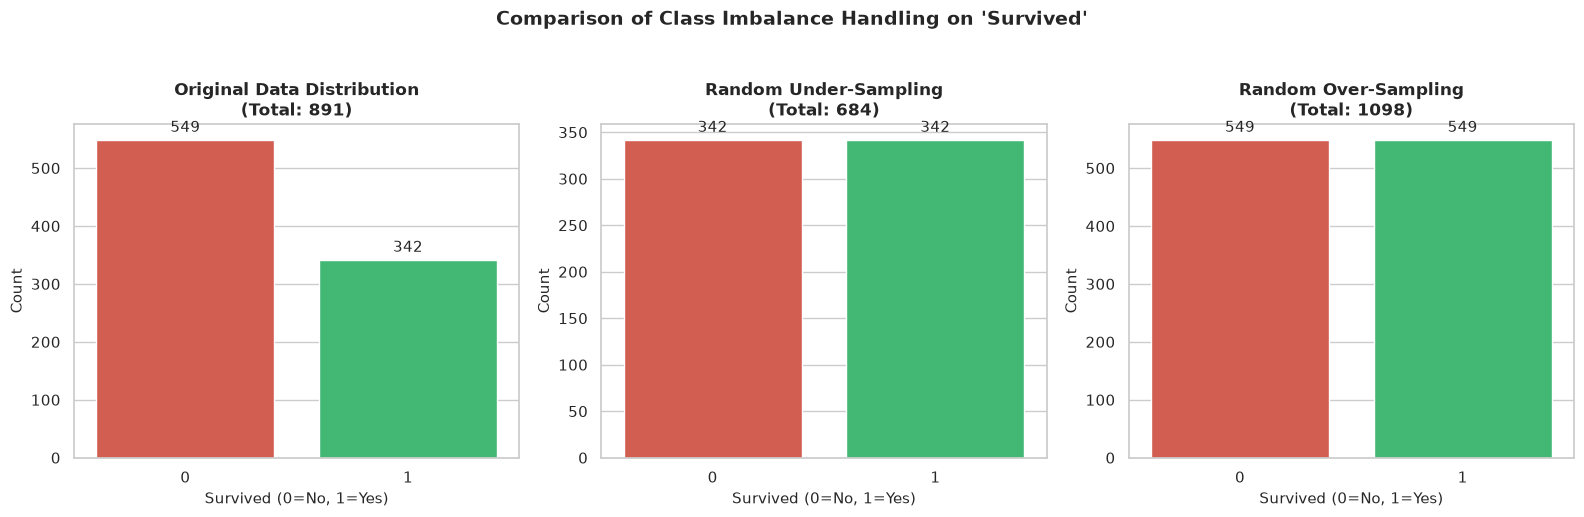

In [29]:
from imblearn.under_sampling import RandomUnderSampler
from imblearn.over_sampling import RandomOverSampler

# Define feature subset and target variable
X = df[["passenger_class", "Age", "Fare"]].copy()
y = df["Survived"].copy()

print("=== ORIGINAL TARGET CLASS DISTRIBUTION ('Survived') ===")
orig_counts = y.value_counts()
print(orig_counts)
print(f"Survival Rate: {(orig_counts[1] / len(y))*100:.2f}%")

# 1. Random Under-Sampling (Reduces majority class 0 to match minority class 1)
rus = RandomUnderSampler(random_state=42)
X_under, y_under = rus.fit_resample(X, y)
print("\n=== RANDOM UNDER-SAMPLING DISTRIBUTION ===")
print(y_under.value_counts())

# 2. Random Over-Sampling (Duplicates minority class 1 to match majority class 0)
ros = RandomOverSampler(random_state=42)
X_over, y_over = ros.fit_resample(X, y)
print("\n=== RANDOM OVER-SAMPLING DISTRIBUTION ===")
print(y_over.value_counts())

# 3. Comparative Visualizations: Histograms of Target Distributions
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# Original Dataset
sns.countplot(x=y, hue=y, ax=axes[0], palette=["#e74c3c", "#2ecc71"], legend=False)
axes[0].set_title(f"Original Data Distribution\n(Total: {len(y)})", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Survived (0=No, 1=Yes)", fontsize=11)
axes[0].set_ylabel("Count", fontsize=11)
for p in axes[0].patches:
    axes[0].annotate(f"{int(p.get_height())}", (p.get_x() + p.get_width() / 2., p.get_height()),
                     ha='center', va='bottom', fontsize=11, xytext=(0, 3), textcoords='offset points')

# Under-Sampled Dataset
sns.countplot(x=y_under, hue=y_under, ax=axes[1], palette=["#e74c3c", "#2ecc71"], legend=False)
axes[1].set_title(f"Random Under-Sampling\n(Total: {len(y_under)})", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Survived (0=No, 1=Yes)", fontsize=11)
axes[1].set_ylabel("Count", fontsize=11)
for p in axes[1].patches:
    axes[1].annotate(f"{int(p.get_height())}", (p.get_x() + p.get_width() / 2., p.get_height()),
                     ha='center', va='bottom', fontsize=11, xytext=(0, 3), textcoords='offset points')

# Over-Sampled Dataset
sns.countplot(x=y_over, hue=y_over, ax=axes[2], palette=["#e74c3c", "#2ecc71"], legend=False)
axes[2].set_title(f"Random Over-Sampling\n(Total: {len(y_over)})", fontsize=12, fontweight="bold")
axes[2].set_xlabel("Survived (0=No, 1=Yes)", fontsize=11)
axes[2].set_ylabel("Count", fontsize=11)
for p in axes[2].patches:
    axes[2].annotate(f"{int(p.get_height())}", (p.get_x() + p.get_width() / 2., p.get_height()),
                     ha='center', va='bottom', fontsize=11, xytext=(0, 3), textcoords='offset points')

plt.suptitle("Comparison of Class Imbalance Handling on 'Survived'", fontsize=14, fontweight="bold", y=1.03)
plt.tight_layout()
plt.show()
